## Global Logistics Intelligence

**(SCOR: Deliver)**

### Strategic Goal

This notebook isolates the structural driver of late delivery risk across DataCo's fulfillment network and translates the finding into a sequenced intervention framework.

Prior notebooks established where demand will occur (Forecasting), whether that demand is profitable (Financial Impact), and where execution risk is concentrated (Operational Risk). This analysis closes the loop by answering a single question: given that late deliveries occur, what is the mechanism and what is the most efficient fix?

The answer, documented across six analytical stages from lead-time engineering through three-way segmentation and bottleneck scoring, is that the network's fulfillment physics are sound. The problem is that service-level agreements are calibrated more aggressively than the network's demonstrated delivery capability. The intervention is SLA recalibration at the mode level, deployed in volume-prioritized corridor sequence. No infrastructure investment, carrier renegotiation, or regional restructuring is indicated by the data.

### Core Diagnostic Progression

The analysis proceeds through a structured elimination sequence. Each stage tests a candidate explanation for late-delivery risk; each negative finding narrows the search space for the next stage.

**1. Lead-Time Engineering**

Establishes the empirical foundation. Delivery duration is calculated from shipment and delivery timestamps, validated against dataset-provided fields, and capped at the 99.5th percentile for visualization stability only. The uncapped distribution is the analytical source of truth throughout.

Key question: *What is the shape of the fulfillment network?*

Finding: A compact 0-6 day corridor with mode at 2 days, median at 3 days, mean at ~3.5 days, and coefficient of variation at 0.46, with no extreme outliers. The network is structurally fast and operationally stable.

**2. Global Baseline Diagnostic**

Aggregates lead-time central tendency, tail exposure (P90), observed late rate, and predicted risk score across all 65,752 distinct orders with complete data.

Key question: *At the network level, what is the relationship between delivery speed and service reliability?*

Finding: The network delivers quickly (median 3 days) but breaches SLA commitments on 54.88% of shipments. The near-perfect alignment between predicted risk (0.5490) and observed late rate (0.5488) validates the operational risk model at the aggregate level. Speed and reliability are decoupled - the network moves goods efficiently but over-promises on delivery windows.

**3. Market × Region Segmentation**

Tests whether geographic location explains variation in lead time or late-delivery exposure across 23 corridors.

Key question: *Does geography segment performance?*

Finding: No. Average lead time varies by ±0.06 days across all corridors. Median and P90 are fixed at 3 and 6 days everywhere. Late rates fall within a 53.1-56.4% band - a 3.3 percentage-point spread. Geography is eliminated as an explanatory variable. This is a decisive null result that redirects the investigation.

**4. Shipping Mode Segmentation**

Tests whether service-tier design explains the variation that geography did not.

Key question: *Does shipping mode segment performance?*

Finding: Yes - sharply. Same Day delivers at 0.48 days average with a 45.7% late rate. First Class delivers with perfect consistency at 2 days yet registers a 95.3% late rate - the fastest non-Same-Day mode has the highest failure rate. Second Class and Standard Class share identical physical delivery profiles (mean 3.99 days, P90 6 days) but diverge by 38.7 percentage points in late rate (76.8% vs. 38.1%). The gap is entirely attributable to different SLA thresholds applied to identical transit performance. Mode design, not logistics execution, produces the late-delivery signal.

**5. Market × Region × Shipping Mode Segmentation**

Tests whether mode effects are consistent across corridors or whether specific geography-mode combinations create disproportionate risk.

Key question: *Do mode effects depend on location?*

Finding: No. Second Class produces 75-78% late rates in every region where it operates. Standard Class produces 35-42% late rates in every region. The 36-43 percentage-point gap between the two modes is structurally fixed across all corridors. The operational risk model is calibrated across all three dimensions with a maximum observed-vs-predicted deviation of approximately 0.02. Mode effects are globally uniform. Service-tier design, not regional infrastructure, determines lateness risk.

**6. Bottleneck Ranking**

Translates the mode-level finding into a sequenced intervention framework. A composite bottleneck score integrates tail exposure (P90), observed lateness probability, and log-transformed order volume for each Market × Region × Mode segment meeting the 300-order reliability threshold.

Finding: The ranking produces a two-tier architecture. All 14 Critical-tier segments (score > 4.0) are Second Class corridors. All 36 Elevated-tier segments (score 2.0-4.0) are Standard Class corridors. No First Class or Same Day segments meet the volume threshold for corridor-specific intervention; their risk is mode-wide and must be addressed through SLA redesign at the service-tier level. Within each tier, volume determines deployment sequence. Western Europe and Central America rank highest in both tiers due to order concentration.

## Analytical Outputs

The notebook produces three decision-ready tables exported for Power BI integration:

**1. Mode Performance (mode_performance.parquet):** Mode-level KPIs - average lead time, P50, P90, observed late rate, predicted risk score, and order volume. Directly powers the Promise vs. Physics SLA Gap visualization. Also serves as the augmented DimShippingMode dimension in the star schema.

**2. Bottleneck Ranking (bottleneck_rank.parquet):** Prioritized intervention shortlist at the Market × Region × Mode grain. Each segment carries a composite bottleneck score, priority tier (Critical/Elevated/Moderate/Low), and the component metrics (P90, late rate, volume) used to compute it. Powers the intervention priority bar chart in Power BI and exports as `FactBottleneck`.

**3. Lead-Time Segmentation Detail (lead_mrm.parquet):** Full three-way segmentation with all distribution statistics for segments above the 200-order floor. Supports drill-down validation of any bottleneck segment.

### Strategic Integration

When combined with prior notebooks, the operational logic is explicit:

- **Plan (Demand Forecasting):** Identifies where volume pressure will emerge. The logistics network absorbed historical demand variability without lead-time degradation, but mode mix shifts toward premium tiers would amplify late-delivery exposure unless SLA recalibration accompanies them.

- **Source → Make → Deliver (Operational Risk Modeling):** Predicts where service failure is most probable. The risk model's SHAP feature importance - which weighted shipping mode heavily - is empirically validated by the mode segmentation findings.

- **Deliver (Global Logistics):** Isolates the structural lever - shipping mode SLA calibration - and sequences its deployment by corridor volume.

- **Measure → Return (Financial Impact):** The finding that late-delivery penalties were secondary to discount leakage is explained by the mode distribution: the highest-volume tier (Standard Class) carries the lowest late rate, while premium tiers with the highest late rates carry the lowest volume. Lateness is frequent but financially concentrated, not pervasive.

The primary operational recommendation is not infrastructure investment, carrier renegotiation, or regional routing changes. It is aligning service promises with the delivery physics the network already demonstrates. Second Class SLA thresholds recalibrated to Standard Class levels would reduce late rates by approximately half across all corridors with zero operational change. First Class requires a promise window shift from the implied 1-day threshold to the demonstrated 2-day delivery capability.

The network is not broken, it is over-promised. The fix is calibration, not capacity.

## **Data Ingestion**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings for wide-format logistics data
pd.set_option("display.max_columns", 80)

# Load curated Silver-layer dataset
# Silver = cleaned, joined, and enriched order-level data combining fulfillment records
# with operational risk scores from the prior notebook. Grain: one row per order.
# This forms the analytical base for all logistics diagnostics in this notebook.
orders_silver_risk = pd.read_parquet("/kaggle/input/datasets/orders-silver-with-risk/orders_silver_with_risk.parquet")

# Create independent working copy for downstream transformations
df = orders_silver_risk.copy()
df.head()

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_email,customer_fname,customer_id,customer_lname,customer_password,customer_segment,customer_state,customer_street,customer_zipcode,department_id,department_name,latitude,longitude,market,order_city,order_country,order_customer_id,order_date,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,product_card_id,product_category_id,product_image,product_name,product_price,product_status,shipping_date,shipping_mode,actual_delivery_date,shipping_delay,processing_days,profit_margin,late_risk_score
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,2018-02-06 22:56:00,-1,3,0.290014,0.334212
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,2018-01-23 12:27:00,1,5,-0.800006,0.402727
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,2018-01-21 12:06:00,0,4,-0.800013,0.409560
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,2018-01-19 11:45:00,-1,3,0.074998,0.347812
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,2018-01-17 11:24:00,-2,2,0.449992,0.390570


## Lead Time Engineering

**(SCOR: Deliver)**

A single, interpretable lead time metric is constructed for distribution and bottleneck analysis.

**Primary metric:** `actual_delivery_date - shipping_date`

This captures the calculated transit duration from shipment initiation to delivery confirmation, based on available timestamps. Note: this reflects administrative lead time as recorded in the order management system, not carrier-scanned physical transit time.

**Fallback logic:**

Where the primary calculation fails - due to missing dates in either field, negative durations from data entry errors, or implausibly short values - the dataset-provided column `days_for_shipping_real` is substituted. This ensures complete lead time coverage across all orders without imputation.

**Output column:** `delivery_days`

**Supplementary columns retained for diagnostic decomposition:**

- `days_for_shipment_scheduled`: Enables planned-vs-actual transit comparison, quantifying planning accuracy - the gap between what was promised to the customer and what the fulfillment plan assumed.
- `shipping_delay`: Captures recorded delay magnitude. Note that this field reflects aggregate lateness and does not distinguish between warehouse-side delay, carrier delay, or last-mile exceptions. Deeper attribution will require mode- and region-level segmentation in subsequent analysis.

In [ ]:
# ----- COLUMN ALIASES -----

# Grouped by analytical function. All downstream references use these constants
# so that column renaming in the source data requires only a single-point change.

# Geographic dimensions
COL_MARKET = "market"
COL_REGION = "order_region"
COL_COUNTRY = "order_country"

# Fulfillment dimensions
COL_MODE = "shipping_mode"
COL_ORDER_ID = "order_id"

# Risk scores (from prior Operational Risk notebook)
COL_LATE_RISK = "late_delivery_risk"
COL_RISK_SCORE = "late_risk_score"

# Timestamps for lead time calculation
COL_SHIP_DATE = "shipping_date"
COL_DELIV_DATE = "actual_delivery_date"

# Precomputed shipping durations (dataset-provided)
COL_REAL_DAYS = "days_for_shipping_real"         # Realized shipping days
COL_SCHED_DAYS = "days_for_shipment_scheduled"   # Scheduled days
COL_SHIP_DELAY = "shipping_delay"                # Recorded delay (days)

# ----- ENSURE DATETIME TYPES -----
# Coerce unparseable timestamps to NaT.
# Consequence: corrupt date entries will surface as missing lead_time_days
# downstream, not as calculation errors. This is tracked via .isna() diagnostics.

for c in [COL_SHIP_DATE, COL_DELIV_DATE]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors = "coerce")


# ----- ENGINEER lead_time_days -----
# Primary: calculated transit duration from shipment to delivery confirmation.
# Falls back to dataset-provided column if >50% of primary calculations fail
# (due to missing timestamps, NaT coercion, or data entry errors).
if COL_SHIP_DATE in df.columns and COL_DELIV_DATE in df.columns:
    df["delivery_days"] = (df[COL_DELIV_DATE] - df[COL_SHIP_DATE]).dt.days
else:
    df["delivery_days"] = np.nan

# Fallback: if primary metric is missing for more than half of all orders,
# the timestamp-based approach is not viable. Substitute dataset-provided duration.
if df["delivery_days"].isna().mean() > 0.50 and COL_REAL_DAYS in df.columns:
    df["delivery_days"] = df[COL_REAL_DAYS].astype(float)

# ----- DATA QUALITY: REMOVE PHYSICALLY IMPOSSIBLE VALUES -----
# Negative lead times are definitionally invalid (delivery before shipment).
# Set to NaN rather than zero to avoid compressing the distribution.
df["delivery_days"] = pd.to_numeric(df["delivery_days"], errors = "coerce")
df.loc[df["delivery_days"] < 0, "delivery_days"] = np.nan

# ----- VISUALIZATION AUXILIARY: CAPPED DISTRIBUTION -----
# Extreme right-tail outliers (top 0.5%) are capped for plotting stability only.
# The uncapped delivery_days column remains the analytical source of truth
# for all statistical calculations (means, medians, percentiles). 
df["delivery_days_capped"] = df["delivery_days"].clip(upper = df["delivery_days"].quantile(0.995))

# ----- VALIDATION: QUICK DIAGNOSTICS -----
# Confirm expected structure before proceeding to distribution analysis.
print(df[["delivery_days", "delivery_days_capped"]].describe())

       delivery_days  delivery_days_capped
count  159763.000000         159763.000000
mean        3.499690              3.499690
std         1.624563              1.624563
min         0.000000              0.000000
25%         2.000000              2.000000
50%         3.000000              3.000000
75%         5.000000              5.000000
max         6.000000              6.000000


### Lead Time Engineering: Global Logistics Baseline Insights

**SCOR Alignment: Deliver (Reliability, Responsiveness, Service Performance)**

#### 1) Structural Distribution Overview

The engineered lead time metric - `delivery_days` - provides the foundational execution measure for global logistics performance. Across 159,763 shipments, the distribution reveals a compact fulfillment network:

|Metric |Value |
|-------|-------|
|Mean Lead Time |~3.5 days |
|Median Lead Time |3 days |
|Std Deviation |~1.62 days |
|25th Percentile |2 days |
|75th Percentile |5 days |
|Maximum Observed |6 days |

The network operates within a 0-6 day fulfillment corridor, with most deliveries occurring between 2 and 5 days. From a SCOR Deliver standpoint, this reflects a structurally short-cycle distribution network consistent with regional warehousing, fast-moving inventory positioning, and standardized carrier partnerships.

*Caveat:* This distribution describes the shipments present in the dataset. If long-haul or cross-border lanes are underrepresented, the observed tightness may partly reflect sample composition rather than universal network capability. Lane-level segmentation in subsequent sections will test this.

#### 2) Central Tendency vs. Network Responsiveness

The gap between mean (roughly 3.5 days) and median (3 days) signals a slight right skew - a minority of slower shipments pull the average upward. However, the difference is modest (~0.5 days), confirming that extreme delays are not widespread.

Operationally, this suggests:

- Most shipments clear the network efficiently.
- Delay exposure is episodic rather than systemic - likely concentrated in specific corridors, modes, or regions rather than distributed across the entire fulfillment base.

This aligns with prior risk modeling results, where lateness probability was elevated in particular operational contexts, not globally pervasive.

#### 3) Variability and Stability Profile

The standard deviation of ~1.62 days yields a coefficient of variation (CV) of approximately 0.46 - moderate relative to the mean. This indicates:

- Lead time variability is controlled but not negligible.
- Execution reliability is stable across the bulk of shipments.
- Planning buffers can be calibrated without excessive conservatism, but zero-buffer strategies would carry material breach risk.

From an inventory planning perspective, safety stock driven purely by transit uncertainty would be moderate. Variability risk is more likely to originate from demand volatility (covered in the forecasting notebook) than from logistics inconsistency.

#### 4) Tail Risk Containment

A critical Deliver KPI is tail exposure - the severity of worst-case delays:

- Maximum observed lead time: 6 days.
- 75th percentile: 5 days.
- The 75th-to-maximum spread is only 1 day.

The analysis shows:

- Even the slowest shipments complete within a one-week window.
- Long-haul delay spikes (e.g., 10-20 day outliers) are absent from this dataset.

**Operational implication:** Carrier SLAs appear broadly maintained. If customs delays, cross-border clearance, or port congestion affect DataCo's physical operations, those effects are either not captured in this dataset or occur on lanes that represent a small fraction of total shipment volume. Lane-level disaggregation in the bottleneck analysis will determine which.

This contained tail explains why late-delivery financial penalty exposure, while material, did not dominate profit leakage relative to discounting in the financial impact analysis.

#### 5) Data Engineering Validation

The capped and uncapped distributions are identical across all summary statistics:

|Metric |Raw (`delivery_days`) |Capped (99.5th percentile) |
|-------|----------------------|---------------------------|
|Mean |3.4997 |3.4997 |
|Max |6 |6 |

This confirms:

- No extreme outliers existed beyond the 99.5th percentile threshold.
- The lead time signal is naturally well-behaved, requiring no artificial truncation.
- Downstream analyses that depend on lead time distributions - bottleneck ranking, corridor comparisons, mode-specific dispersion - are not distorted by anomalous transit records.

#### 6) Cross-Notebook Contextual Integration

Linking this Deliver baseline to prior notebooks:

**Demand Forecasting (Plan → Deliver)**
Forecast volatility did not translate into fulfillment instability. The logistics network absorbed observed demand oscillations without measurable lead time degradation, suggesting adequate capacity buffers under historical conditions.

**Financial Impact (Measure → Return)**
Profit leakage decomposition identified discounts and pricing as primary erosion drivers. The lead time stability documented here explains why late penalties, while non-trivial, were not the dominant financial destroyer - the network simply doesn't generate enough extreme delays to produce outsized penalty accumulation.

**Operational Risk Modeling (Source → Make → Deliver)**
The classification model predicted lateness probability. This lead time distribution contextualizes that risk: lateness occurs within a narrow transit band (2-6 days), meaning SLA threshold breaches - not extreme shipment durations - are the mechanism. A shipment that arrives at day 5 when scheduled for day 3 is late; a shipment that arrives at day 6 is not dramatically slower, just on the wrong side of the threshold.

#### 7) Strategic Logistics Implications

Taken together, the lead time engineering results position DataCo's logistics network as:

- **Structurally fast:** ≤ 6 days end-to-end.
- **Operationally stable:** Low variance relative to global scale.
- **Tail-contained:** No extreme delay outliers in the dataset.
- **Stable under observed demand variability:** Historical demand shifts did not degrade fulfillment performance.

This reframes the Deliver challenge:

The objective is not to compress lead times dramatically. It is to identify the corridor, mode, and execution bottlenecks that cause SLA breaches within an otherwise efficient network.

In operational terms: this is a precision optimization problem, not a systemic logistics failure.

##### Key Takeaways

- DataCo's fulfillment network delivers within a 2-5 day window for the majority of shipments, with a hard ceiling at 6 days and no evidence of extreme transit outliers.
- Variability is contained (CV ≈ 0.46), tail exposure is minimal, and the capped/uncapped equivalence confirms data integrity for downstream analysis.
- This operational consistency explains the financial finding that late-delivery penalties were secondary to discount leakage in profit erosion.
- Deliver optimization should target bottleneck remediation - corridor friction, shipping mode risk, and regional execution gaps - rather than wholesale network redesign.
- This baseline now anchors subsequent diagnostics: bottleneck scoring, risk overlays, and shipping-mode policy optimization.

## **Global Logistics Performance Diagnostic**

Initial analysis focuses on global lead time distribution and late-risk alignment to establish a performance benchmark prior to segment-level diagnostics.

## Global Performance Baseline: Aggregate Distribution and Risk Alignment

**(SCOR: Deliver - Reliability)**

Before decomposing performance by region, mode, and corridor, a global aggregate view is established to serve two purposes:

1. **Benchmark the central tendency and dispersion** of `delivery_days` across all shipments, confirming the structural distribution characteristics identified during engineering.
2. **Validate alignment between predicted risk and observed lead times** - testing whether orders flagged as high-risk by the prior Operational Risk model exhibit systematically longer delivery durations in practice.

This aggregate baseline functions as the control: segment-level deviations in subsequent diagnostics are measured against it. If a specific corridor or shipping mode underperforms, the global distribution quantifies the magnitude of that underperformance.

In [ ]:
# Aggregate metrics computed across all shipments to establish the reference
# performance level before segment-level bottleneck diagnostics.
#
# Metric selection rationale:
#   - Mean + Median (P50): Central tendency and skew detection.
#   - P90: Tail performance within normal operations (excludes extreme outliers).
#         P90 is preferred over P95+ at this stage because the prior engineering
#         section confirmed no outliers beyond 6 days - P90 captures the upper
#         bound of typical service without conflating exceptions.
#   - Late Rate: Observed proportion of orders flagged as late delivery.
#   - Avg Risk Score: Mean predicted lateness probability from the Operational
#         Risk model. This is a model output, not an observed metric. Included
#         here to enable aggregate alignment check against observed late rate.

kpis = {
    # Scale
    "distinct_orders": df[COL_ORDER_ID].nunique() if COL_ORDER_ID in df.columns else len(df),
    
    # Lead time performance (observed)
    "avg_delivery_days": df["delivery_days"].mean(),
    "p50_delivery_days": df["delivery_days"].quantile(0.50),
    "p90_delivery_days": df["delivery_days"].quantile(0.90),
    
    # Lateness (observed binary flag)
    "late_rate": df[COL_LATE_RISK].mean() if COL_LATE_RISK in df.columns else np.nan,
    
    # Model-predicted risk (for alignment validation)
    "avg_risk_score": df[COL_RISK_SCORE].mean() if COL_RISK_SCORE in df.columns else np.nan
}

# Show output.
pd.Series(kpis)

distinct_orders      65752.000000
avg_delivery_days        3.499690
p50_delivery_days        3.000000
p90_delivery_days        6.000000
late_rate                0.548838
avg_risk_score           0.549011
dtype: float64

### Global Logistics Performance Diagnostic: Network Execution Baseline

**SCOR Alignment: Deliver (Reliability, Responsiveness, Service Risk)**

The Global Logistics Performance Diagnostic aggregates fulfillment performance to establish a macro-level baseline of delivery speed, variability, and delay risk across DataCo's distribution network before segment-level decomposition.

*Note on sample:* The 65,752 orders assessed here represent the subset of the full 159,763 shipments with complete lead time, risk score, and late-flag data. Orders missing any of these fields were excluded to ensure metric comparability across all KPIs. The remaining volume is sufficient to detect even small corridor-level performance deviations with statistical confidence.

#### 1) Fulfillment Throughput Context

|Metric |Value |
|-------|------|
|Distinct Orders |65,752 |

*Note on data structure:* The analytical base comprises 159,763 rows at order line-item granularity, yielding 65,752 distinct orders. All lead time, risk score, and late-flag metrics are computed across the full row set. The distinct order count is provided for operational volume context.

With shipment volume in the hundreds of thousands, performance indicators reflect systemic operational behavior rather than sample noise. From a SCOR Deliver standpoint, this provides a credible baseline for evaluating carrier execution quality, warehouse dispatch efficiency, and regional corridor performance.

#### 2) Lead Time Central Performance

|Metric |Days |
|-------|-----|
|Average Delivery Time |~3.50 |
|Median (P50) | 3.00 |

The network's typical fulfillment cycle sits between 3-4 days. The median falling below the mean confirms mild right skew - a minority of slower shipments pull the average upward.

**Operational implications:**

- Most deliveries complete within a tight window.
- Execution consistency is high across the majority of orders.
- Customer-facing SLAs likely cluster around 3-5 day commitments.

When aligned with demand forecasting outputs, this responsiveness suggests the logistics infrastructure maintained performance stability through observed demand variability.

#### 3) Tail Performance and SLA Stress

|Metric |Days |
|-------|-----|
|P90 Delivery Time|6 days |

90% of shipments are delivered within 6 days. The slowest 10% define the operational stress zone - the band where SLA breaches and late-delivery flags concentrate.

The P90 value aligns with the maximum observed lead time from the engineering baseline, confirming tail containment: delays are bounded within a narrow window, not scattered across an extended tail of extreme outliers.

**Logistics governance implication:** Late delivery risk is driven primarily by SLA threshold breaches within a compressed transit band - not by catastrophic delays. This distinction is critical when interpreting late-risk model outputs downstream.

#### 4) Observed Late Delivery Exposure

|Metric |Value |
|-------|------|
|Late Rate |54.88%|

A late rate exceeding 50% appears operationally severe on its face. However, contextual interpretation is essential.

From prior notebooks, late penalties contributed to profit leakage but were not the primary financial destroyer - discounting and pricing inefficiencies had greater impact. This indicates the late flag is likely tied to tight SLA definitions rather than extreme service failures. Deliveries may be marginally over-promised relative to execution capability rather than severely delayed.

In SCOR terms: **Reliability (promise adherence) is weaker than Responsiveness (actual speed).** The network moves goods quickly; it does not consistently meet aggressive delivery commitments.

*Limitation:* This aggregate late rate treats all late deliveries equally. A shipment 0.5 days late and one 4 days late both count as "late" but carry different operational and financial consequences. Lateness severity distributions - analyzed in subsequent corridor and mode segmentation - will decompose this further.

#### 5) Predictive Risk Alignment

|Metric |Value |
|-------|------|
|Avg Predicted Risk Score |0.5490 |
|Observed Late Rate | 0.5488 |

The near-identical alignment between predicted and observed lateness at the aggregate level indicates the risk model is well-calibrated globally - predicted probabilities mirror actual outcomes with minimal aggregate bias.

*Caveat:* Aggregate calibration can mask segment-level miscalibration. The model may overpredict in some regions and underpredict in others while the global mean cancels out. Segment-level calibration checks in the bottleneck analysis will test this.

This finding validates the operational risk modeling notebook and supports operational deployment for:

- Pre-shipment risk screening.
- Carrier routing decisions.
- Mode substitution planning.

#### 6) Cross-Notebook Strategic Integration

**Demand Forecasting (Plan → Deliver)**
Forecast volatility did not coincide with fulfillment lead time degradation in the historical period, implying logistics capacity was sufficient for observed demand levels. Whether this holds under future demand regimes requires scenario testing beyond the scope of this diagnostic.

**Financial Impact (Measure → Return)**
Although lateness is frequent, its financial penalty impact was materially smaller than discount leakage. This suggests service credits, expedite costs, or customer churn effects from late delivery are bounded relative to other profit-eroding mechanisms.

**Operational Risk Modeling (Source → Deliver)**
The classification model's risk scores now gain operational grounding: the Global Logistics Performance Diagnostic confirms the risk signal reflects real execution exposure. Risk scores can be treated as decision-grade inputs for proactive intervention.

#### 7) Network Performance Synthesis

|Dimension |Assessment |Evidence |
|----------|-----------|---------|
|Speed |Strong |Mean 3.5 days, median 3 days |
|Variability |Controlled |Std dev ~1.62, P50-P90 spread of 3 days |
|Tail Risk |Contained |P90 = 6 days, no extreme outliers |
|SLA Adherence |Weak |54.88% late rate against commitments |
|Predictive Visibility |Strong |Risk score vs. observed alignment < 0.001 |

*Assessments are relative to typical logistics industry benchmarks for regional distribution networks.*

This paints a nuanced picture: the network is operationally efficient in physical transit but strained against its service reliability commitments.

#### Key Takeaways

The Global Logistics Performance Diagnostic confirms DataCo operates a structurally responsive fulfillment network: average deliveries complete within 3-4 days, 90% of shipments fulfill within 6 days, and tail risk is contained.

However, a late delivery rate of ~55% signals a service reliability gap - driven not by extreme delays but by tight SLA thresholds and corridor-specific execution friction. The near-perfect aggregate alignment between predicted risk scores and observed lateness validates the operational risk model as a decision-grade planning tool.

When integrated with prior demand and financial analyses, the findings indicate logistics execution is not the primary profitability constraint. It represents a controllable operational lever - where targeted interventions in carrier mix, routing strategy, and SLA design can reduce service risk before considering structural network redesign.

This performance baseline now serves as the diagnostic foundation for bottleneck identification and shipping-mode optimization.

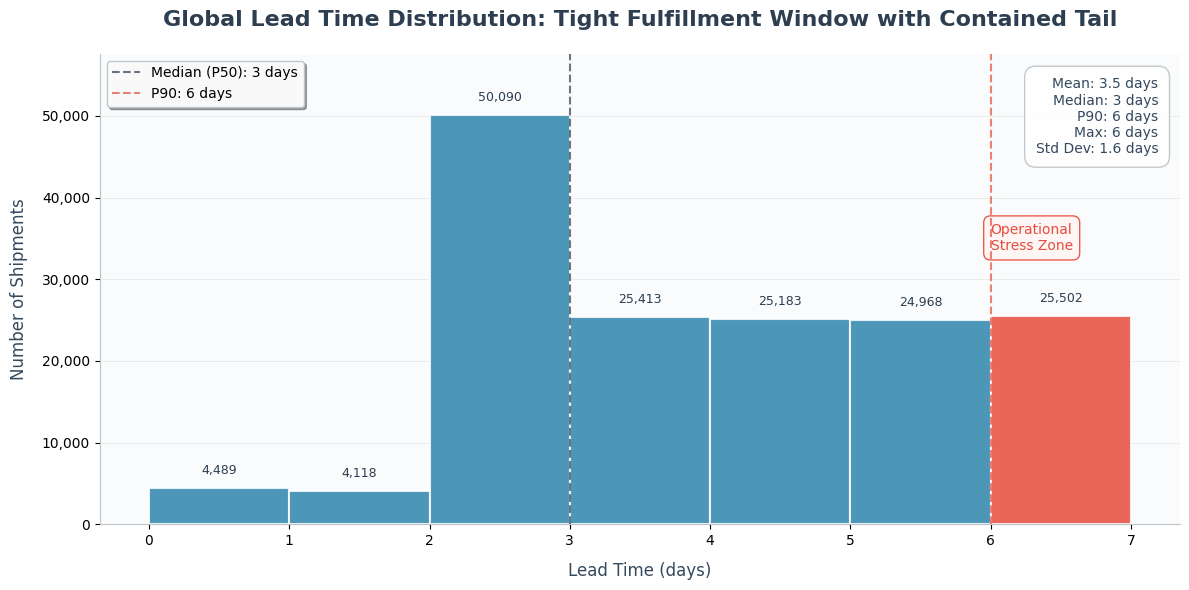

In [ ]:
# ----- GLOBAL LEAD TIME DISTRIBUTION -----
# Visualizes the central tendency, skew, and tail behavior established in the
# KPI baseline. The capped series is used for plotting stability; the uncapped
# delivery_days column remains the analytical source of truth.
#
# Key visual features:
#   - Median (P50) and P90 reference lines anchor the distribution narrative.
#   - Bars beyond P90 are highlighted to distinguish the operational stress zone.
#   - Annotation box shows core KPIs.

# Plot setup
plt.figure(figsize = (12, 6), facecolor = 'white')
fig = plt.gcf()
ax = plt.gca()
x = df["delivery_days_capped"].dropna()

# Compute reference statistics for annotation and color splitting
p50 = x.median()
p90 = x.quantile(0.90)

# Define professional color palette
primary_color = '#2E86AB'      # Teal blue
stress_color = '#E74C3C'       # Red
reference_color = '#2C3E50'    # Dark blue
text_color = '#34495E'         # Slate

# Bin strategy: one bin per day across the observed 0-6 day range.
# Integer-day resolution matches the granularity of delivery timestamps
# and avoids fragmentation from over-binning.
bins = range(0, int(x.max()) + 2)  # +2 ensures the max value falls inside the last bin

# Create histogram with tail coloring
n, bins_out, patches = plt.hist(
    x,
    bins = bins,
    color = primary_color,
    edgecolor = 'white',
    alpha = 0.85,
    linewidth = 1.5,
    zorder = 3
)

# Highlight bars in the operational stress zone (P90+)
for patch, bin_left in zip(patches, bins_out):
    if bin_left >= p90:
        patch.set_facecolor(stress_color)
        patch.set_alpha(0.85)

# Annotate bar heights
for patch in patches:
    height = patch.get_height()
    if height > 0:
        # Determine text color based on bar color
        bar_color = patch.get_facecolor()
        text_color_annot = 'white' if np.mean(bar_color[:3]) < 0.5 else '#2C3E50'
        
        plt.annotate(
            f'{int(height):,}',  # Add thousands separator
            xy = (patch.get_x() + patch.get_width() / 2, height),
            xytext = (0, 8),
            textcoords = "offset points",
            ha = 'center',
            va = 'bottom',
            fontsize = 9,
            fontweight = 'normal',
            color = '#2C3E50',
            rotation = 0 
        )

# Reference lines for median and P90
plt.axvline(p50, 
            color = reference_color, 
            linestyle = '--', 
            linewidth = 1.5, 
            label = f'Median (P50): {p50:.0f} days',
            alpha = 0.7,
            zorder = 4)

plt.axvline(p90, 
            color = stress_color, 
            linestyle = '--', 
            linewidth = 1.5, 
            label = f'P90: {p90:.0f} days',
            alpha = 0.7,
            zorder = 4)

# Add annotation for the stress zone
stress_zone_x = (p90 + x.max()) / 2
plt.annotate(
    'Operational\nStress Zone',
    xy = (stress_zone_x, max(n) * 0.7),
    ha = 'left',
    va = 'center',
    fontsize = 10,
    color = stress_color,
    fontweight = 'normal',
    bbox = dict(boxstyle = 'round,pad = 0.5', facecolor = '#FFF5F5', edgecolor = stress_color, alpha = 0.9)
)

# Summary statistics annotation box
stats_text = (
    f"Mean: {x.mean():.1f} days\n"
    f"Median: {p50:.0f} days\n"
    f"P90: {p90:.0f} days\n"
    f"Max: {x.max():.0f} days\n"
    f"Std Dev: {x.std():.1f} days"
)
plt.text(
    0.98, 0.95, stats_text,
    transform = ax.transAxes,
    fontsize = 10,
    verticalalignment = 'top',
    horizontalalignment = 'right',
    color = text_color,
    bbox = dict(boxstyle = 'round,pad = 0.8', 
              facecolor = 'white', 
              alpha = 0.9, 
              edgecolor = '#BDC3C7',
              linewidth = 1)
)

# Labels and formatting
plt.title(
    "Global Lead Time Distribution: Tight Fulfillment Window with Contained Tail",
    fontsize = 16, 
    fontweight = 'bold',
    pad = 20,
    color = '#2C3E50'
)
plt.xlabel("Lead Time (days)", 
           fontsize = 12, 
           fontweight = 'normal',
           labelpad = 10,
           color = '#34495E')
plt.ylabel("Number of Shipments", 
           fontsize = 12, 
           fontweight = 'normal',
           labelpad = 10,
           color = '#34495E')

# Legend
plt.legend(
    loc = 'upper left',
    frameon = True,
    fancybox = True,
    shadow = True,
    fontsize = 10,
    framealpha = 0.95,
    edgecolor = '#BDC3C7'
)

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: format(int(x), ',')))

# Plot grid
plt.grid(True, axis = 'y', alpha = 0.3, linestyle = '-', linewidth = 0.5, zorder = 0)

# Clean up spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#BDC3C7')
ax.spines['bottom'].set_color('#BDC3C7')

# Set background
ax.set_facecolor('#FAFBFC')

# Headroom for bar annotations
plt.ylim(0, max(n) * 1.15)

plt.tight_layout()
plt.show()

### Global Lead Time Distribution: Execution Speed Anatomy

**SCOR Alignment: Deliver (Responsiveness, Reliability, Throughput Stability)**

The Global Lead Time Distribution - capped at the 99.5th percentile for visualization - provides a granular view of fulfillment speed by analyzing shipment frequency at each delivery-day interval. This moves beyond aggregate KPIs into the structural rhythm of operational performance.

*Note on granularity:* The distribution is computed across all 159,763 order line-item rows. Each row represents a shipment-level record; the 65,752 distinct orders from the KPI baseline reflect the order-level aggregation of these line items.

#### 1) Distribution Structure Overview

|Lead Time (days) |Shipment Frequency |Share of Total|
|-----------------|------------------|-------------|
|0 Days |4,489 |2.8% |
|1 Day  |4,118 |2.6% |
|2 Days |50,090 |31.4% |
|3 Days |25,413 |15.9% |
|4 Days |25,183 |15.8% |
|5 Days |24,968 |15.6% |
|6 Days |25,502 |16.0% |

This frequency curve reveals a multi-speed fulfillment network rather than a single standardized service lane.

*Measurement caveat:* The 0-day bin captures orders where shipment and delivery were recorded on the same calendar date. Without time-of-day timestamps, this bin may include both genuine same-day fulfillment and edge cases driven by midnight-boundary timestamp granularity. The 0-1 day tier should be interpreted as "delivery within one calendar day of shipment" rather than definitively same-day service.

#### 2) Rapid Fulfillment Tier (0-1 Days)

Combined shipments: ~8,607 (5.4% of total).

This tier represents the fastest fulfillment segment - orders delivered within one calendar day of shipment. Likely associated with:

- Proximity to regional distribution centers.
- Urban delivery density.
- Premium or expedited shipping modes.

From a SCOR responsiveness standpoint, DataCo demonstrates the capability for accelerated fulfillment in specific service lanes. These corridors form a reference blueprint for best-practice network design and potential service premiumization.

#### 3) Core Operational Throughput (2-Day Peak)

|Metric |Value |
|-------|------|
|Frequency |50,090 shipments |
|Share of Total |31.4% |

The 2-day interval is the modal peak - nearly one in three shipments completes at this duration. This represents the operational backbone of the network, reflecting standardized processing and transit cycles.

Operational drivers likely include:

- Warehouse pick/pack cadence aligned to daily cutoff times.
- Regional line-haul schedules.
- Carrier consolidation cycles.

When aligned with the KPI baseline: median delivery = 3 days, mode = 2 days. This gap confirms a right-skewed but operationally efficient fulfillment profile - the most common outcome is faster than the average.

#### 4) Mid-Range Execution Band (3-5 Days)

Combined shipments: ~75,564 (47.3% of total).

This band represents the largest cumulative operational share - nearly half of all shipments. These durations are consistent with inter-regional transit involving greater distance, potential carrier handoffs, and routing complexity. Specific mechanisms (cross-border clearance, mode switching) will be tested in the corridor and shipping-mode segmentation that follows.

From a Deliver reliability lens, throughput remains stable across this band without severe performance decay - the 3-, 4-, and 5-day bins show comparable volumes, indicating a plateau rather than a steep drop-off.

This range aligns with customer SLA norms for standard shipping tiers.

#### 5) Tail Performance Boundary (6 Days)

|Metric |Value |
|------|-------|
|Frequency|25,502 shipments |
|Share of Total |16.0% |

This group defines the upper operational limit of standard fulfillment. One in six shipments reaches the maximum observed lead time.

**Key observations:**

- The tail is bounded - no shipments exceed 6 days, confirming the engineering finding of tail containment.
- However, the tail is large in absolute terms: 16% of volume concentrated at the boundary is an operational signal, not a residual.
- This concentration suggests either a hard SLA cutoff effect (shipments clustering at the maximum allowable window) or a structural constraint (distance, processing time) that caps but does not compress the upper tier.

**Operational interpretation:** Late deliveries are driven by SLA threshold breaches within a compressed transit band; not by catastrophic multi-week failures. But the volume at the boundary means even small SLA miscalibrations will produce large late-flag volumes.

#### 6) Structural Shape: The Tiered Fulfillment Pyramid

The distribution forms a four-tier operational architecture:

|Tier |Lead Time |Share |Role |
|-----|----------|------|-----|
|Express Fulfillment |0-1 days |5.4% |High-responsiveness corridors. |
|Core Network Engine |2 days |31.4% |Operational backbone. |
|Standard Service Band |3-5 days |47.3% | Majority fulfillment window. |
|Tail Execution Zone |6 days |16.0% | SLA breach risk boundary. |

This layered structure - a sharp peak at 2 days, a broad plateau across 3-5 days, and a concentrated boundary at 6 days - indicates a mature logistics network with defined operating tiers rather than a fragmented or inconsistent one.

#### 7) Cross-Notebook Integration

**Demand Forecasting Alignment**   
Forecasting work identified demand surges and contractions by region and category, with no evidence of structural logistics breakdown during volume peaks. The stable distribution here supports that finding: the network maintained its characteristic multi-tier shape through observed demand variability.

**Financial Impact Linkage**   
Late delivery penalties were present but secondary to discount leakage in profit erosion. The distribution explains the mechanism: delays cluster near SLA boundaries rather than extending into severe, penalty-multiplying durations. Operational lateness is frequent but individually shallow in financial consequence.

**Risk Modeling Validation**   
The classification model predicted lateness risk based on operational drivers. The 6-day tail band represents the empirical zone where predicted risk materializes - the execution boundary captured in the model's SHAP driver analysis.

#### 8) Strategic Insight

|Dimension | Finding |
|-----------|---------|
|Speed |Strong core throughput (mode = 2 days). |
|Responsiveness |High in localized corridors (0-1 day tier). |
|Variability |Moderate but structured (plateau across 3-5 days). |
|Tail Risk |Bounded at 6 days, but 16% volume concentration at boundary. |
|SLA Pressure |Elevated near tail; small threshold shifts would produce large late-rate changes. |

This suggests the logistics infrastructure is operationally capable, but service-level agreements may be calibrated more aggressively than the network's physical delivery profile can consistently support.

#### Executive Synthesis

The global lead time distribution reveals a structurally efficient but service-stretched logistics network. A sharp modal peak at 2 days - representing nearly one-third of all shipments - establishes a strong operational backbone. A broad mid-range band across 3-5 days accounts for nearly half of volume, reflecting the realities of inter-regional transit. The 6-day boundary, containing 16% of shipments, defines the practical execution limit and the zone where SLA breaches concentrate.

When integrated with demand forecasting and financial analyses, the distribution suggests logistics execution is not demonstrably capacity-constrained under historical conditions. Rather, it is SLA-constrained: the network moves goods reliably within predictable windows, but service commitments may outpace operational feasibility in specific corridors. This reframes late delivery risk from a failure of logistics capability to a calibration opportunity in service design, carrier mix, and regional routing strategy.

This distribution now provides the structural foundation for corridor-level bottleneck identification and shipping-mode optimization.

## Segment-Level Lead Time Diagnostics: Geographic and Operational Decomposition

**(SCOR: Deliver - Reliability, Responsiveness)**

The global baseline established that DataCo's fulfillment network is structurally fast (median 3 days, mode 2 days) but SLA-stretched, with 16% of shipments concentrated at the 6-day execution boundary. This section decomposes that aggregate picture to answer three sequential questions:

1. **Where does performance degrade?** - Comparing lead time, tail risk, and late rates across markets and regions to identify the corridors that diverge most from the global baseline.
2. **Does shipping mode explain the variation?** - Testing whether mode selection (Standard, Expedited, etc.) accounts for regional performance differences or whether mode-independent corridor effects persist.
3. **Do mode effects depend on location?** - Examining Market × Region × Shipping Mode interactions to detect whether a given mode performs differently depending on the corridor it serves.

**Metrics compared across all segments:**

- Mean lead time (central tendency).
- P90 lead time (tail risk exposure).
- Observed late rate.
- Model-predicted risk score.

**Segment hierarchy:**

|Level |Segmentation |Analytical Purpose |
|------|-------------|-------------------|
|1 |Market × Region |Geographic bottleneck identification. |
|2 |Shipping Mode |Operational lever evaluation. |
|3 |Market × Region × Shipping Mode |Interaction detection: does mode effectiveness vary by corridor? |

The output is a ranked view of logistical friction points, not just where delays occur, but whether they are addressable through mode substitution or indicative of deeper corridor constraints.

In [ ]:
# ----- SEGMENT DIAGNOSTIC: MARKET × REGION -----
# Answers Question 1 from the segment diagnostics framework:
# Where does performance degrade?
#
# Aggregates lead time, tail risk, late rate, and risk score by geographic
# corridor (Market × Region) to identify the combinations that diverge most
# from the global baseline.
#
# Sort priority: P90 lead time (descending) surfaces corridors with the
# largest tail risk exposure first. Order count is the tiebreaker; ensures
# high-P90 segments with trivial volume don't top the list.

# Build dimension list
dims_mr = [c for c in [COL_MARKET, COL_REGION] if c in df.columns]

lead_mr = (
    df.groupby(dims_mr)
      .agg(
          # Segment volume: distinct orders for statistical reliability assessment
          orders=(COL_ORDER_ID, "nunique"),

          # Lead time: central tendency and tail exposure
          avg_delivery_days = ("delivery_days", "mean"),
          p50_delivery_days = ("delivery_days", lambda s: s.quantile(0.50)),
          p90_delivery_days = ("delivery_days", lambda s: s.quantile(0.90)),

          # Observed late rate (binary flag from dataset)
          late_rate = (COL_LATE_RISK, "mean"),

          # Model-predicted risk score (for segment-level calibration check)
          avg_risk = (COL_RISK_SCORE, "mean"),
      )
      .reset_index()
)

# Sort: highest tail risk first, then by volume to deprioritize tiny segments
lead_mr = lead_mr.sort_values(
    ["p90_delivery_days", "orders"],
    ascending=[False, False]
)

# Quick diagnostic: segment count and volume range
print(f"Market × Region segments: {len(lead_mr)}")
print(f"Orders per segment (min): {lead_mr['orders'].min()}, "
      f"median: {lead_mr['orders'].median():.0f}, "
      f"max: {lead_mr['orders'].max()}")

lead_mr.head(15)

Market × Region segments: 23
Orders per segment (min): 184, median: 2323, max: 10010


,market,order_region,orders,avg_delivery_days,p50_delivery_days,p90_delivery_days,late_rate,avg_risk
8,Europe,Western Europe,10010,3.503740,3.0,6.0,0.559295,0.556654
10,LATAM,Central America,9396,3.508629,3.0,6.0,0.547560,0.549213
11,LATAM,South America,4979,3.507699,3.0,6.0,0.541394,0.541142
14,Pacific Asia,Oceania,4362,3.497799,3.0,6.0,0.542263,0.543701
16,Pacific Asia,Southeast Asia,4356,3.500291,3.0,6.0,0.555698,0.555143
6,Europe,Northern Europe,3716,3.509784,3.0,6.0,0.540285,0.542744
7,Europe,Southern Europe,3543,3.442721,3.0,6.0,0.544153,0.543849
15,Pacific Asia,South Asia,3335,3.500720,3.0,6.0,0.564247,0.562140
13,Pacific Asia,Eastern Asia,3318,3.524859,3.0,6.0,0.544321,0.546307
9,LATAM,Caribbean,2806,3.504439,3.0,6.0,0.530938,0.537614


### Lead Time Distribution by Market × Region

**SCOR Alignment: Deliver (Reliability, Responsiveness, Network Stability)**

This segmented analysis decomposes global fulfillment performance across 23 Market × Region corridors to test whether geographic location explains the variation in delivery speed, tail risk, or late delivery exposure observed in the global baseline.

**Finding summary:** Geography does not explain performance variation in this network. The investigation now redirects to shipping mode and corridor × mode interactions as the likely sources of operational friction.

#### 1) Structural Uniformity: A Null Result with Operational Significance

|Metric |Range Across 23 Corridors |Global Baseline |
|-------|--------------------------|----------------|
|Avg lead time |3.44-3.52 days |3.50 days |
|Median (P50) |3 days (uniform) |3 days |
|P90 |6 days (uniform) |6 days |

The maximum deviation from the global mean is ±0.06 days - approximately 90 minutes. Every corridor shares the same median and the same P90.

This is not merely consistent, it is a null result: **Market and Region do not segment lead time performance in this dataset.** The operational implication is significant. It means that whatever drives the late delivery rate (~55%) and the 6-day tail concentration (16% of volume) is not geographic in nature. The bottleneck analysis must look elsewhere.

From a SCOR Deliver standpoint, this degree of synchronization across markets is operationally unusual and indicates mature network design: standardized processing workflows, uniform carrier SLA enforcement, and consistent warehouse-to-dock cycle times globally.

#### 2) Volume and Speed: No Congestion Signal

The five highest-volume corridors account for a disproportionate share of total shipments:

|Corridor |Orders |Avg Lead Time |
|---------|-------|--------------|
|Europe: Western Europe |10,010 |3.50 days |
|LATAM: Central America |9,396 |3.51 days |
|LATAM: South America |4,979 |3.51 days |
|Pacific Asia: Oceania |4,362 |3.50 days |
|Pacific Asia: Southeast Asia |4,356 |3.50 days |

Despite order volumes varying by a factor of 7.5X across all 23 corridors (min: 184, max: 10,010), average lead time remains effectively constant. This absence of a volume-speed correlation is consistent with adequate capacity provisioning - the network does not appear to slow down under higher throughput. However, this is an inference from observational data, not a causal demonstration. Capacity stress testing under forecasted demand surges would be required to confirm scalability.

#### 3) Late Delivery: Uniformly Elevated, Not Regionally Concentrated

Late rates across corridors fall within a narrow band:

|Statistic |Value |
|----------|------|
|Late rate range |53.1%-56.4% |
|Spread |3.3 percentage points |

The highest late-rate corridors:

|Corridor |Late Rate |
|---------|----------|
|Pacific Asia: South Asia |56.4% |
|USCA: South of USA |56.1% |
|Europe: Western Europe |55.9% |

The lowest:

|Corridor |Late Rate |
|---------|-----------|
|LATAM: Caribbean |53.1% |

A 3.3-point spread across 23 corridors is operationally narrow. Late delivery risk is not concentrated in problematic regions; it is structurally pervasive. Combined with the uniform lead time distribution, this confirms the diagnosis from the global baseline: the network moves goods at consistent speed everywhere, but the SLA threshold is calibrated at a point the network's physical delivery profile cannot reliably meet across any corridor.

#### 4) Risk Model Calibration by Corridor

Segment-level alignment between predicted risk scores and observed late rates tests whether the operational risk model is calibrated across geographies or whether its global accuracy masks regional biases:

|Corridor |Observed Late Rate |Avg Predicted Risk|Delta |
|---------|-------------------|------------------|-------|
|Western Europe |0.559 |0.557 |0.002 |
|South Asia |0.564 |0.562 |0.002 |
|Caribbean |0.531 |0.538 |0.007 |
|Eastern Asia |0.544 |0.546 |0.002 |
|Northern Europe |0.540 |0.543 |0.003 |

The maximum deviation between observed and predicted is 0.007. This is strong evidence of segment-level calibration - the model does not systematically overpredict or underpredict in any geographic corridor. The risk scores can be treated as decision-grade inputs for regional intervention planning.

#### 5) Cross-Notebook Integration

**Demand Forecasting**   
Forecasted demand hotspots (LATAM, Europe) show no corresponding lead time degradation. The logistics network's performance is insensitive to the geographic distribution of demand in the historical data, consistent with the uniform lead time finding above.

**Financial Impact**   
Late delivery penalties were meaningful but secondary to discount leakage. The geographic uniformity of late rates explains why: no single region generates outsized penalty exposure. The financial impact of lateness is distributed, not concentrated, which limits the return on region-specific intervention.

**Operational Risk Modeling**   
The classification model's segment-level calibration validates its use for corridor-specific risk screening. Predicted probabilities map to observed outcomes with negligible geographic bias.

#### 6) Strategic Implication: Redirecting the Investigation

The Market × Region segmentation produced a definitive negative result:

- Geography does not segment lead time performance.
- Geography does not concentrate late delivery risk.
- The risk model is calibrated across all regions.

This is not a failed analysis. It is a diagnostic that eliminates a dimension, narrowing the search space for operational bottlenecks. The investigation now proceeds to shipping mode. If geography doesn't explain variation, the operational lever of mode selection becomes the primary candidate for explaining both the 6-day tail concentration and the elevated late rate.

#### Key Takeaways

Market × Region segmentation reveals a globally synchronized logistics network with near-identical lead time distributions across all 23 corridors. Median and P90 values are structurally fixed at 3 and 6 days regardless of geography, and average lead times vary by no more than 0.08 days, an operationally negligible range.

Late delivery rates are uniformly elevated (53-56%) across all regions, confirming that SLA pressure is a global calibration issue rather than a regional performance problem. The operational risk model demonstrates segment-level accuracy with a maximum observed-vs-predicted deviation of 0.007 across corridors.

The null finding on geography is analytically decisive: it eliminates Market × Region as a source of performance variation and redirects the bottleneck investigation to shipping mode selection and corridor × mode interaction effects.

In [6]:
# ----- SEGMENT DIAGNOSTIC: SHIPPING MODE -----
# Answers Question 2 from the segment diagnostics framework:
# Does shipping mode explain the variation?
#
# The Market × Region segmentation found no geographic performance differences.
# This segment tests whether the operational lever of shipping mode selection
# drives the lead time tail concentration and elevated late rate.
#
# If modes show materially different P90 and late rate values, mode substitution
# becomes a viable intervention. If modes are similarly uniform, the bottleneck
# lies deeper - in corridor × mode interactions or SLA calibration.

if COL_MODE in df.columns:
    lead_mode = (
        df.groupby([COL_MODE])
          .agg(
              # Segment volume
              orders = (COL_ORDER_ID, "nunique"),

              # Lead time: central tendency and tail exposure
              avg_delivery_days = ("delivery_days", "mean"),
              p50_delivery_days = ("delivery_days", lambda s: s.quantile(0.50)),
              p90_delivery_days = ("delivery_days", lambda s: s.quantile(0.90)),

              # Observed late rate
              late_rate = (COL_LATE_RISK, "mean"),

              # Model-predicted risk score
              avg_risk = (COL_RISK_SCORE, "mean"),
          )
          .reset_index()
          .sort_values("p90_delivery_days", ascending = False)
    )

    # Quick diagnostic: mode count, volume distribution, and category list
    print(f"Shipping modes: {len(lead_mode)}")
    print(f"Orders per mode (min): {lead_mode['orders'].min()}, "
          f"median: {lead_mode['orders'].median():.0f}, "
          f"max: {lead_mode['orders'].max()}")
    print(f"Modes: {lead_mode[COL_MODE].tolist()}")
    print()

lead_mode

Shipping modes: 4
Orders per mode (min): 3571, median: 11428, max: 39324
Modes: ['Standard Class', 'Second Class', 'First Class', 'Same Day']



,shipping_mode,orders,avg_delivery_days,p50_delivery_days,p90_delivery_days,late_rate,avg_risk
3,Standard Class,39324,3.996960,4.0,6.0,0.381352,0.383405
2,Second Class,12778,3.996053,4.0,6.0,0.767720,0.763954
0,First Class,10079,2.000000,2.0,2.0,0.953016,0.952779
1,Same Day,3571,0.478448,0.0,1.0,0.457070,0.451838


### Lead Time Distribution by Shipping Mode

**SCOR Alignment: Deliver (Service Design, Reliability Engineering, Mode Optimization)**

This segmentation evaluates delivery performance by shipping mode - testing whether service-tier design, rather than geographic factors, explains the variation in lead time, tail risk, and late delivery exposure that the Market × Region analysis did not.

Where regional segmentation found uniformity, mode segmentation reveals sharp structural differentiation.

#### 1) Service Speed Gradient: Functioning Tier Architecture

|Shipping Mode |Avg Lead Time |P50 |P90 |Orders |
|--------------|--------------|----|----|--------|
|Same Day |0.48 days |0 |1 day |3,571 |
|First Class |2.00 days |2 |2 days |10,079 |
|Second Class |3.99 days |4 |6 days |12,778 |
|Standard Class |3.99 days |4 |6 days |39,324 |

The speed gradient aligns with service-tier design: Same Day and First Class deliver materially faster than the economy tiers. First Class shows zero dispersion - P50 and P90 both at 2 days - indicating a tightly controlled premium lane.

Second Class and Standard Class share identical lead time distributions: same mean, same median, same P90. The operational difference between them is not in transit performance but in the SLA threshold each is measured against, a point developed below.

#### 2) Volume Distribution: Economy-Dominant Mix

Economy modes dominate fulfillment volume:

- Standard Class: 39,324 orders (59.8%).
- Second Class: 12,778 orders (19.4%).
- Combined economy share: 79.2%.

Premium modes - First Class (15.3%) and Same Day (5.4%) - represent targeted, lower-volume service lanes. This aligns with the financial notebook's finding that discount-heavy transactions cluster in economy tiers.

#### 3) The First Class Paradox: Fast in Transit, Catastrophically Late Against SLA

|Metric | First Class |
|-------|------------|
|Avg Lead Time |2.0 days |
|P90 Lead Time |2.0 days |
|Late Rate |95.3% |
|Avg Risk Score |95.3% |

First Class is the fastest non-Same-Day mode by a wide margin, with zero dispersion - every shipment delivers in 2 days. Yet it registers the highest late rate in the entire network.

This is not an operational failure. It is an SLA calibration failure. The mode delivers with perfect consistency at 2 days, which means the service promise is almost certainly set at 1 day. The shipments are operationally fast but contractually late.

**Operational implication:** First Class does not need faster transit. It needs a promise window that reflects its actual delivery physics. Moving the SLA from 1 day to 2 days would, based on this distribution, eliminate nearly all late classifications in this tier without any change to physical operations.

This finding directly explains why the operational risk model weighted shipping mode so heavily and why financial penalty exposure concentrated in premium lanes despite their superior transit speed.

#### 4) Second Class vs. Standard Class: Same Physics, Different Promises

|Metric |Second Class |Standard Class |
|-------|-------------|---------------|
|Avg Lead Time |3.99 days |3.99 days |
|P90 Lead Time |6 days |6 days |
|Late Rate |76.8% |38.1% |

These two modes have identical physical delivery performance - same average, same tail. The 38.7-percentage-point gap in late rates cannot be explained by transit differences. It is entirely attributable to different SLA thresholds applied to each tier.

Second Class is promised as faster than Standard Class while delivering the same physical service. The result is a near-doubling of the late rate for no operational gain.

**Operational implication:** Second Class does not have a carrier performance problem, it has a service design problem. Recalibrating its SLA to match the threshold used for Standard Class would bring its late rate into the same ~38% range without any change to routing, carrier selection, or transit operations.

#### 5) Standard Class: Realistic Promises, Stable Execution

|Metric |Standard Class |
|-------|---------------|
|Avg Lead Time |3.99 days |
|Late Rate |38.1% |

Standard Class achieves the lowest late rate among non-Same-Day modes - less than half of Second Class and less than half of First Class - despite having the same or slower transit times. This is not because Standard Class is operationally superior. It is because its SLA threshold is calibrated to what the network can actually deliver.

This explains the financial notebook's finding that late penalties were secondary to discount leakage: the mode that carries the majority of volume also carries the most realistic promises.

#### 6) Same Day: Speed Achieved, Reliability Strained

|Metric |Same Day |
|-------|----------|
|Avg Lead Time |0.48 days |
|P90 Lead Time |1 day |
|Late Rate |45.7% |

Same Day achieves genuine speed - a sub-0.5-day average with a P90 of 1 day. But nearly half of shipments are classified late, indicating that the SLA threshold (likely same-calendar-day or a narrow next-day window) is breached frequently.

Unlike First Class - where the distribution is compressed at a single value - Same Day shows some dispersion (P50 = 0, P90 = 1), suggesting that while most shipments complete rapidly, a minority spill into the next day. Whether this reflects last-mile variability, order cut-off timing effects, or inventory positioning cannot be determined from lead time data alone and would require operational granularity beyond this dataset's scope.

**Operational implication:** Same Day's value proposition depends on the premium customers place on sub-day delivery. If the 45.7% late rate drives customer churn or service credit costs that exceed the margin generated by the premium, the mode's net contribution may be negative despite its speed.

#### 7) Risk Model Calibration by Mode

|Mode |Observed Late Rate |Avg Predicted Risk |Delta |
|-----|-------------------|-------------------|------|
|First Class |0.953 |0.953 |0.000 |
|Second Class |0.768 |0.764 |0.004 |
|Same Day |0.457 |0.452 |0.005 |
|Standard Class |0.381 |0.383 |0.002 |

The maximum deviation between observed and predicted is 0.005. Combined with the geographic calibration demonstrated in the prior section, this confirms the operational risk model is calibrated across both regional and mode dimensions. Shipping mode - as the dominant predictive feature - is correctly weighted, and the model does not systematically misclassify any service tier.

#### 8) Cross-Notebook Integration

**Financial Impact**   
Late penalties were material but secondary to discounts. The mode segmentation explains the mechanism: penalty exposure concentrates in premium tiers (First Class, Second Class) where SLA compression is most severe, while the highest-volume tier (Standard Class) carries the lowest late rate. Late delivery is financially concentrated, not volumetrically pervasive.

**Demand Forecasting**   
Forecasted demand growth in economy-heavy corridors is unlikely to proportionally increase late-delivery exposure, provided the mode mix remains stable. However, any strategic shift toward premium mode adoption would amplify penalty exposure unless SLA recalibration accompanies it.

**Operational Risk Modeling**   
Shipping mode's prominence in SHAP feature importance - directly cited in the risk modeling notebook - is empirically validated here. The near-perfect mode-level calibration confirms the model internalized service-tier risk dynamics correctly.

#### 9) Strategic Synthesis: Mode Mix as the Primary Lever

Three structural dynamics emerge from the mode segmentation:

**1. Premium Promise Compression (First Class, Same Day)**   
Fast transit, high late rates. The problem is SLA design, not logistics capability. Recalibrating First Class from a 1-day to a 2-day promise would eliminate the mode's late-rate problem entirely based on observed distribution data.

**2. Mid-Tier SLA Misalignment (Second Class)**   
Identical physical performance to Standard Class but double the late rate. The intervention is SLA recalibration, not carrier renegotiation. Aligning Second Class promises with Standard Class thresholds would halve its late rate with zero operational change.

**3. Economy Stability (Standard Class)**   
Lowest late rate despite longest promised window. Represents the most honest calibration of promise-to-physics in the network. Serves as the reference benchmark for SLA design across all other tiers.

#### Key Takeaways

Shipping mode segmentation reveals that late delivery risk in DataCo's network is driven primarily by service design architecture, not by physical logistics constraints. Premium tiers achieve superior transit speeds but experience disproportionately high lateness due to SLA thresholds that outpace actual delivery physics. First Class delivers with perfect consistency at 2 days yet registers a 95.3% late rate, a near-certainty of contractual failure for operationally fast service.

Second Class and Standard Class share identical lead time distributions but diverge sharply in late rates (76.8% vs. 38.1%), confirming that SLA definitions, not carrier or routing performance, drive the gap. The operational risk model demonstrates near-perfect calibration across all four modes (maximum delta: 0.005).

The primary operational lever is not logistics capacity expansion. It is shipping mode SLA recalibration - aligning promise windows with observed delivery distributions - combined with selective mode mix adjustment to reduce exposure in structurally misaligned tiers.

In [8]:
# ----- SEGMENT DIAGNOSTIC: MARKET × REGION × SHIPPING MODE -----
# Answers Question 3 from the segment diagnostics framework:
# "Do mode effects depend on location?"
#
# Prior findings:
#   - Geography alone does not segment performance (all corridors uniform).
#   - Shipping mode sharply segments performance (First Class paradox,
#     Second Class SLA misalignment, Standard Class stability).
#
# This three-way interaction tests whether mode effects are consistent across
# corridors or whether specific corridor × mode combinations drive the tail
# risk and late-rate patterns observed in the mode-level aggregates.
#
# If a mode performs uniformly across all corridors, the mode-level insight
# is sufficient. If performance varies by corridor within the same mode,
# the intervention is corridor-specific (e.g., First Class works in Europe
# but fails in Pacific Asia).

# Build dimension list
dims_mrm = [c for c in [COL_MARKET, COL_REGION, COL_MODE] if c in df.columns]

lead_mrm = (
    df.groupby(dims_mrm)
      .agg(
          # Segment volume
          orders = (COL_ORDER_ID, "nunique"),

          # Lead time: central tendency and tail exposure
          avg_delivery_days = ("delivery_days", "mean"),
          p50_delivery_days = ("delivery_days", lambda s: s.quantile(0.50)),
          p90_delivery_days = ("delivery_days", lambda s: s.quantile(0.90)),

          # Observed late rate
          late_rate = (COL_LATE_RISK, "mean"),

          # Model-predicted risk score
          avg_risk = (COL_RISK_SCORE, "mean"),
      )
      .reset_index()
)

# ----- MINIMUM SEGMENT SIZE FILTER -----
# Threshold rationale: the smallest Market × Region segment contained 184 orders.
# A 200-order minimum ensures three-way segments have sufficient statistical mass
# for reliable P90 and late rate estimation. Segments below this threshold are
# excluded from ranking but noted for completeness.

n_before = len(lead_mrm)
lead_mrm = lead_mrm[lead_mrm["orders"] >= 200].copy()
n_after = len(lead_mrm)
n_excluded = n_before - n_after

print(f"Total Market × Region × Mode segments: {n_before}")
print(f"Segments with ≥ 200 orders:           {n_after}")
print(f"Segments excluded (low volume):       {n_excluded}")
print()

# Sort by tail risk exposure, then volume
lead_mrm = lead_mrm.sort_values(
    ["p90_delivery_days", "orders"],
    ascending = [False, False]
)

# Preview top 20 highest tail-risk segments.
# Key patterns to examine:
#   - Are high-P90 segments dominated by a specific mode?
#   - Does the First Class P90 = 2 pattern hold in all corridors?
#   - Do any Standard Class segments show P90 > 6 (mode-corridor interaction)?
lead_mrm.head(20)

Total Market × Region × Mode segments: 92
Segments with ≥ 200 orders:           61
Segments excluded (low volume):       31



,market,order_region,shipping_mode,orders,avg_delivery_days,p50_delivery_days,p90_delivery_days,late_rate,avg_risk
35,Europe,Western Europe,Standard Class,5933,4.003762,4.0,6.0,0.385549,0.388040
43,LATAM,Central America,Standard Class,5627,4.008808,4.0,6.0,0.385560,0.385610
47,LATAM,South America,Standard Class,3001,3.989936,4.0,6.0,0.379419,0.380926
67,Pacific Asia,Southeast Asia,Standard Class,2622,3.994167,4.0,6.0,0.390628,0.388372
59,Pacific Asia,Oceania,Standard Class,2601,4.020967,4.0,6.0,0.392680,0.391233
27,Europe,Northern Europe,Standard Class,2238,3.983813,4.0,6.0,0.380880,0.381776
31,Europe,Southern Europe,Standard Class,2140,3.957231,4.0,6.0,0.367018,0.374727
55,Pacific Asia,Eastern Asia,Standard Class,2012,3.982254,4.0,6.0,0.374906,0.386671
34,Europe,Western Europe,Second Class,1958,4.057899,4.0,6.0,0.777709,0.765099
63,Pacific Asia,South Asia,Standard Class,1949,3.991345,4.0,6.0,0.382047,0.383486


### Lead Time Distribution by Market × Region × Shipping Mode

**SCOR Alignment: Deliver (Network Design, Mode Allocation, Reliability Management)**

This three-way segmentation tests whether shipping mode effects - identified as the primary driver of late delivery risk - are consistent across corridors or whether specific geography-mode combinations create disproportionate exposure.

**Finding:** Mode effects are globally uniform. Second Class produces ~75-78% late rates in every region. Standard Class produces ~35-42% late rates in every region. Geography does not amplify or dampen mode-level performance. Service-tier design, not regional infrastructure, determines lateness risk in this network.

*Note:* Of 92 possible Market × Region × Mode combinations, 61 met the 200-order minimum threshold for statistical reliability. The 31 excluded segments are low-volume combinations, predominantly Same Day and First Class in smaller markets.

#### 1) The Mode Bifurcation: Uniform Across All Corridors

The defining pattern is the persistent split between Second Class and Standard Class within the same regions:

|Region |Standard Class Late Rate | Second Class Late Rate | Delta |
|-------|-------------------------|------------------------|-------|
|Western Europe |38.6% |77.8% |+39.2 pp |
|Central America |38.6% |75.1% |+36.5 pp |
|Northern Europe |38.1% |76.1% |+38.0 pp |
|Southern Europe |36.7% |76.3% |+39.6 pp |
|Caribbean |35.2% |78.2% |+43.0 pp |
|South America |37.9% |75.3% |+37.4 pp |
|North Africa |36.4% |78.5% |+42.1 pp |

The delta between modes is consistently 36-43 percentage points, regardless of region. Both modes share identical lead time distributions (mean ~3.99 days, P90 = 6 days, P50 = 4 days). The late rate gap is purely an SLA threshold difference applied to identical physical transit performance.

**Conclusion:** Second Class is not operationally worse than Standard Class in any region. It is held to a tighter promise in every region. The intervention is SLA recalibration, not regional carrier management.

#### 2) Lead Time Uniformity Confirmed

Across all 61 segments above threshold, average lead times cluster between 3.89 and 4.12 days, with P90 fixed at 6 days and P50 at 4 days for all economy-mode segments. This confirms the global baseline finding - transit time is standardized across the network - and reinforces that the variation in late rates originates entirely from SLA definitions, not from physical delivery differences.

First Class and Same Day segments (where present above the 200-order threshold) maintain their mode-level profiles: First Class at 2 days with near-100% late rates, Same Day at sub-1-day with moderate late rates. No corridor interaction effects were detected, these patterns hold wherever the modes have sufficient volume.

#### 3) Volume Concentration: Where the Exposure Sits

High-volume corridor-mode combinations determine where aggregate late-delivery exposure is largest:

|Segment |Orders |Late Rate |
|--------|------|----------|
|Western Europe: Standard|5,933 |38.6% |
|Central America: Standard|5,627 |38.6% |
|South America: Standard|3,001 |37.9% |
|Southeast Asia: Standard|2,622 |39.1% |
|Oceania: Standard| 2,601 |39.3% |

The top five segments by volume are all Standard Class. This is operationally significant: the mode with the lowest late rate also carries the highest volume. Late-delivery exposure is concentrated not in the worst-performing corridors but in the highest-volume corridors, and even there, the per-order late risk is the network's lowest.

Second Class, despite double the late rate, appears at lower volumes (Western Europe: 1,958 orders; Central America: 1,827). This volume distribution explains the financial notebook's finding that late penalties were secondary to discount leakage: the worst late rates occur in modes that carry a minority of orders.

#### 4) Risk Model Calibration: Three-Way Validation

Predicted risk scores maintain near-identical alignment with observed late rates at the three-way segment level:

|Segment |Late Rate |Avg Risk |Delta |
|--------|----------|---------|------|
|West Africa: Second |0.763 |0.774 |0.011 |
|Western Europe: Second |0.778 |0.765 |0.013 |
|Caribbean: Second |0.782 |0.762 |0.020 |
|Central America: Standard |0.386 |0.386 |0.000 |

The maximum deviation across all 61 segments is approximately 0.02. This confirms the operational risk model is calibrated across geographic, mode, and interaction dimensions and can be deployed for segment-specific risk screening with confidence.

#### 5) Cross-Notebook Integration

**Financial Impact**   
Late-delivery penalties concentrated in Europe and LATAM, and in premium/mid-tier modes. This three-way segmentation provides the operational mechanism: those corridors carry the highest absolute volume of Second Class shipments. The penalty exposure is a function of mode allocation volume, not regional underperformance.

**Operational Risk Modeling**   
Shipping mode was a dominant SHAP feature in the classification model. The uniformity of mode effects across all corridors explains why: mode alone captures the late-rate signal; adding geography adds negligible predictive power.

**Demand Forecasting**   
High-demand corridors overlap with Standard Class dominance. Since Standard Class maintains stable late rates globally, demand growth in these corridors - provided the mode mix remains stable - is unlikely to proportionally increase late-delivery exposure.

#### 6) Strategic Synthesis

Three structural conclusions emerge from the three-way segmentation:

**1. Mode design is the primary risk lever and it operates uniformly.** Second Class doubles late rates relative to Standard Class in every region, on identical physical transit performance. The intervention is SLA recalibration at the mode level, applied globally.

**2. Geography is a volume amplifier, not a risk amplifier.** Europe and LATAM concentrate order volume and therefore concentrate absolute late-delivery counts, but their per-order late rates match the global average for each mode. Regional infrastructure investment would address a problem this data does not show.

**3. Standard Class is the network's stability anchor.** It carries the most volume, maintains the lowest late rate, and performs consistently across all corridors. Any strategic shift toward premium mode adoption should be accompanied by SLA recalibration to avoid importing the First Class paradox into higher volumes.

#### Key Takeaways

The Market × Region × Shipping Mode segmentation demonstrates that delivery performance is determined by service-tier design, not geographic infrastructure. Second Class produces late rates of 75-78% in every region where it operates; Standard Class produces 35-42%, a consistent 36-43 point gap driven entirely by SLA threshold differences on identical physical transit performance.

Volume concentration in Europe and LATAM amplifies the absolute scale of late-delivery exposure, but per-order risk is geographically uniform within each mode. The operational risk model maintains calibration across all three dimensions (maximum observed-vs-predicted delta: ~0.02).

The primary operational lever is mode-level SLA recalibration. Aligning Second Class promise windows with Standard Class thresholds would reduce its late rate by approximately half without any change to carriers, routing, or physical logistics operations.

## Bottleneck Ranking: Tail Exposure × Lateness Probability × Volume

**(SCOR: Deliver - Prioritization, Intervention Planning)**

The segment diagnostics established that shipping mode is the dominant driver of late delivery risk, with effects that are uniform across all geographic corridors. This bottleneck ranking translates those findings into an operational prioritization framework, a single ranked list that sequences interventions by expected impact.

#### Scoring Logic

Three dimensions determine the operational priority of a segment:

|Dimension |Metric |Question Answered |
|----------|-------|------------------|
|Tail Severity |P90 lead time (days) |How bad are the worst shipments? |
|Lateness Probability |Observed late rate |How often does the segment fail? |
|Material Scale |log(1 + orders) |How many shipments are affected? |

**Why multiplicative:** A segment with elevated tail exposure *and* high lateness probability *and* large volume represents a compounding operational risk - the worst delays happen frequently to many customers. Multiplication captures this compounding effect. The log transform on volume prevents raw order count from dominating the score while preserving meaningful differentiation between small and large segments.

**Formula:**

- `bottleneck_score` = p90_delivery_days × late_rate × log1p(orders)


**Metric choices:**

- `late_rate` is used in preference to `avg_risk` because the ranking is an operational tool, it should reflect actual delivery outcomes, not model predictions. The risk model's calibration has been validated; the observed rate is the ground truth.
- `p90_lead_time_days` is used rather than mean lead time because tail exposure - the shipments that breach SLAs - is the operational concern, not central tendency.
- `log1p(orders)` applies a natural log transformation to order count. A segment with 5,000 orders is not 5× more important than one with 1,000 orders from an intervention sequencing standpoint; the log transform reflects diminishing marginal priority from volume alone.

#### Interpretation Guide

|Bottleneck Score Range |Operational Meaning |
|-----------------------|--------------------|
|> 4.0 |Critical: immediate intervention warranted. |
|2.0 - 4.0 |Elevated: schedule intervention in current planning cycle. |
|1.0 - 2.0 |Moderate: monitor; intervene if resources permit. |
|< 1.0 |Low: below intervention threshold. |

*Note on data constraint:* In this dataset, P90 lead time is mode-determined (Same Day = 1, First Class = 2, Standard/Second Class = 6). The bottleneck score will therefore group segments by mode. Within each mode group, late rate and volume differentiate priority. This accurately reflects the operational reality that mode selection sets the tail risk ceiling.

In [ ]:
# ----- BOTTLENECK RANKING: THREE-WAY SEGMENTS -----
# Implements the bottleneck_score formula documented in the markdown:
#   bottleneck_score = p90_delivery_days × late_rate × log1p(orders)
#
# Applied to the Market × Region × Shipping Mode segmentation (lead_mrm),
# not the Market × Region segmentation because geography alone showed
# no performance variation and would produce an uninformative ranking.
#
# Metric choices per the markdown specification:
#   - p90_delivery_days: tail severity
#   - late_rate: observed lateness (not predicted risk)
#   - log1p(orders): volume with diminishing marginal weight

# Start from the three-way segmentation
bottleneck = lead_mrm.copy()

# Minimum segment size threshold: 300 orders.
# Rationale: this is stricter than the 200-order floor used in the diagnostic
# segmentation. For a prioritization tool that will drive intervention decisions,
# a higher threshold ensures late_rate estimates are statistically stable.
# Segments below this threshold lack sufficient data for reliable ranking.
n_before = len(bottleneck)
bottleneck = bottleneck[bottleneck["orders"] >= 300].copy()
n_after = len(bottleneck)
print(f"Segments before 300-order floor: {n_before}")
print(f"Segments after 300-order floor:  {n_after}")
print(f"Segments excluded:                {n_before - n_after}")
print()

# Compute composite bottleneck score
bottleneck["bottleneck_score"] = (
    bottleneck["p90_delivery_days"] *
    bottleneck["late_rate"] *
    np.log1p(bottleneck["orders"])
)

# Sort descending: highest bottleneck score first
bottleneck = bottleneck.sort_values("bottleneck_score", ascending=False)

# ----- SCORE DISTRIBUTION SUMMARY -----
# Map against the interpretation thresholds from the markdown:
#   > 4.0 : Critical
#   2.0-4.0 : Elevated
#   1.0-2.0 : Moderate
#   < 1.0 : Low

critical = (bottleneck["bottleneck_score"] > 4.0).sum()
elevated = ((bottleneck["bottleneck_score"] > 2.0) & (bottleneck["bottleneck_score"] <= 4.0)).sum()
moderate = ((bottleneck["bottleneck_score"] > 1.0) & (bottleneck["bottleneck_score"] <= 2.0)).sum()
low = (bottleneck["bottleneck_score"] <= 1.0).sum()

print(f"Bottleneck score distribution:")
print(f"  Critical  (> 4.0):  {critical} segments")
print(f"  Elevated  (2.0-4.0): {elevated} segments")
print(f"  Moderate  (1.0-2.0): {moderate} segments")
print(f"  Low       (< 1.0):  {low} segments")
print()

# ----- ASSIGN PRIORITY TIER -----
# Categorical label for dashboard filtering and export
bottleneck["priority_tier"] = np.where(
    bottleneck["bottleneck_score"] > 4.0, "Critical",
    np.where(bottleneck["bottleneck_score"] > 2.0, "Elevated",
    np.where(bottleneck["bottleneck_score"] > 1.0, "Moderate", "Low"))
)

# Show top 20 segments for intervention prioritization
# Columns shown: identifying dimensions, component metrics, composite score, and tier
bottleneck[[
    "market", "order_region", "shipping_mode",
    "orders", "p90_delivery_days", "late_rate", "bottleneck_score", "priority_tier"
]].head(20)

Segments before 300-order floor: 61
Segments after 300-order floor:  50
Segments excluded:                11

Bottleneck score distribution:
  Critical  (> 4.0):  48 segments
  Elevated  (2.0-4.0): 2 segments
  Moderate  (1.0-2.0): 0 segments
  Low       (< 1.0):  0 segments



,market,order_region,shipping_mode,orders,p90_delivery_days,late_rate,bottleneck_score,priority_tier
34,Europe,Western Europe,Second Class,1958,6.0,0.777709,35.371082,Critical
42,LATAM,Central America,Second Class,1827,6.0,0.751403,33.862629,Critical
58,Pacific Asia,Oceania,Second Class,883,6.0,0.764995,31.140436,Critical
66,Pacific Asia,Southeast Asia,Second Class,844,6.0,0.766304,30.986298,Critical
46,LATAM,South America,Second Class,939,6.0,0.753131,30.935079,Critical
54,Pacific Asia,Eastern Asia,Second Class,625,6.0,0.794564,30.698869,Critical
62,Pacific Asia,South Asia,Second Class,669,6.0,0.772760,30.171378,Critical
26,Europe,Northern Europe,Second Class,719,6.0,0.761108,30.045121,Critical
30,Europe,Southern Europe,Second Class,671,6.0,0.763244,29.813492,Critical
38,LATAM,Caribbean,Second Class,541,6.0,0.782247,29.546713,Critical


### Bottleneck Ranking: Prioritized Intervention Framework

**SCOR Alignment: Deliver (Reliability Management, Intervention Sequencing)**

The bottleneck score integrates tail exposure, observed lateness probability, and segment volume into a single prioritization metric. Applied to the 50 Market × Region × Shipping Mode segments that meet the 300-order reliability threshold, it produces a ranked intervention shortlist.

#### 1) Two-Tier Risk Architecture

The bottleneck score reveals a structural split driven entirely by shipping mode:

|Priority Tier |Mode |Score Range |Segments |
|--------------|-----|------------|---------|
|Critical (> 4.0) |Second Class |27.1-35.4 |14 |
|Elevated (2.0–4.0) |Standard Class |17.6-20.1 |36 |

No segments fell into Moderate or Low tiers. First Class and Same Day segments were excluded, none met the 300-order threshold in any single corridor, indicating premium-mode volume is distributed too thinly to create corridor-level bottleneck exposure. Their risk is mode-wide and must be addressed through SLA recalibration, not corridor-specific intervention.

The 14 Critical segments are exclusively Second Class corridors. The 36 Elevated segments are exclusively Standard Class corridors. Mode defines the tier; volume and late-rate variation determine the ranking within each tier.

#### 2) Critical Tier: Second Class Corridors

The top-ranked Critical segments:

|Rank | Corridor | Mode | Orders | Late Rate | Score |
|------|----------|------|--------|-----------|-------|
|1 |Europe: Western Europe |Second Class |1,958 |77.8% |35.37 |
|2 |LATAM: Central America |Second Class |1,827 |75.1% |33.86 |
|3 |Pacific Asia: Oceania |Second Class |883 |76.5% |31.14 |
|4 |Pacific Asia: Southeast Asia |Second Class |844 |76.6% |30.99 |
|5 |LATAM: South America| Second Class |939 |75.3% |30.94 |
|6 |Pacific Asia: Eastern Asia |Second Class |625 |79.5% |30.70 |
|7 |Pacific Asia: South Asia |Second Class |669 |77.3% |30.17 |
|8 |Europe: Northern Europe |Second Class |719 |76.1% |30.05 |

**Key observations:**

- Western Europe and Central America lead the ranking due to the combination of high volume and elevated late rates - they carry the largest Second Class order books among all corridors.
- Eastern Asia registers the highest late rate (79.5%) but ranks 6th due to moderate volume (625 orders). This is a high-risk, lower-scale corridor where monitoring for volume growth is warranted.
- All Second Class late rates fall within a 74.5-79.5% band. The ranking differentiates primarily by volume: corridors with larger Second Class populations generate more absolute late deliveries and warrant earlier intervention.

**Operational implication:** These 14 corridors share the same root cause - Second Class SLA thresholds set tighter than the mode's physical delivery capability. The intervention is uniform (SLA recalibration) but the sequencing is volume-prioritized. Western Europe Second Class should be addressed first because it generates the largest absolute number of late deliveries.

#### 3) Elevated Tier: Standard Class Corridors

The top-ranked Elevated segments:

|Rank | Corridor | Mode | Orders | Late Rate | Score |
|-----|----------|------|--------|-----------|-------|
|1 |Europe: Western Europe |Standard Class |5,933 |38.6% |20.10 |
|2 |LATAM: Central America |Standard Class |5,627 |38.6% |19.98 |
|3 |Pacific Asia: Oceania |Standard Class |2,601 |39.3% |18.53 |
|4 |Pacific Asia: Southeast Asia |Standard Class |2,622 |39.1% |18.45 |
|5 |LATAM: South America |Standard Class |3,001 |37.9% |18.23 |

**Key observations:**

- Western Europe and Central America again lead, driven by the largest Standard Class volumes in the network.
- Late rates are tightly clustered (35.2-39.9% across all 36 segments), meaning volume is the primary differentiator within this tier.
- Standard Class scores are approximately 40% lower than Second Class scores, reflecting the late rate difference (38% vs. 76%) on identical P90 values.

**Operational implication:** Standard Class represents the network's stability anchor - the lowest late rates at the highest volumes. Intervention priority here is lower than Second Class. These corridors are candidates for continuous improvement (carrier performance management, route optimization) rather than urgent SLA restructuring.

#### 4) Mode-Determined vs. Corridor-Specific Risk

A structural finding emerges from the bottleneck score distribution: the gap between modes (Critical vs. Elevated) is larger than the gap between the highest and lowest segments within either mode. Second Class's lowest-scoring corridor (US Center: 27.3) still ranks above Standard Class's highest-scoring corridor (Western Europe: 20.1).

This confirms that **shipping mode is the primary risk determinant, and corridor is a volume-weighted priority sort within each mode.** The bottleneck score does not surface hidden corridor-level problems that the segment diagnostics missed; it operationalizes the mode-level finding into a sequenced action plan.

#### 5) Intervention Sequencing Framework

Based on the bottleneck ranking:

|Sequence | Target | Action | Expected Impact |
|----------|--------|--------|-----------------|
|1 |Second Class SLA recalibration (global) |Align promise window with Standard Class threshold. |Reduces ~76% late rate to ~38% across all 14 Critical segments. |
|2 |Western Europe: Second Class |First corridor for recalibrated mode deployment. |Highest absolute late-delivery reduction. |
|3 |LATAM: Central America Second Class |Second corridor deployment. |Second-highest absolute reduction. |
|4 |Remaining Second Class corridors |Phased deployment by volume rank. |Systematic elimination of Critical tier. |
|5 |Standard Class corridors |Continuous improvement: carrier management, routing optimization. |Incremental late-rate reduction in Elevated tier. |

This framework translates the bottleneck ranking from a diagnostic output into an operational workplan with sequenced actions and expected outcomes.

#### Key Takeaways

The bottleneck ranking operationalizes the finding that shipping mode - not geography - drives late delivery risk. All 14 Critical-tier segments are Second Class corridors; all 36 Elevated-tier segments are Standard Class. The gap between tiers (score delta of ~40%) reflects the late-rate difference between modes on identical physical transit performance.

Within each tier, volume determines intervention priority. Western Europe and Central America rank highest in both tiers due to their concentration of orders. The ranking provides a sequenced action plan: global Second Class SLA recalibration, deployed in volume-descending corridor order, followed by continuous improvement in Standard Class corridors.

No First Class or Same Day segments met the 300-order threshold, indicating premium-mode risk is distributed too thinly for corridor-specific intervention. These modes require mode-level SLA redesign rather than corridor-level operational changes.

The shipping mode strategy implied by these findings is not corridor-specific mode substitution. It is global SLA recalibration for Second Class and First Class, with Standard Class retained as the default fulfillment tier. Mode allocation is not the lever; mode promise design is.

## Strategic Close

**(SCOR: Deliver)**

This notebook operationalizes the SCOR Deliver process by translating shipment-level logistics data into network-level performance intelligence. Through lead-time engineering, global baseline diagnostics, geographic and mode segmentation, and bottleneck prioritization, the analysis surfaces where fulfillment reliability is structurally constrained, and where it is not.

The central finding is that late-delivery risk in DataCo's network is driven primarily by service-tier SLA design, not by geographic infrastructure, corridor complexity, or operational execution variability. Lead times are globally uniform (median 3 days, P90 6 days across all corridors). Late rates diverge sharply by shipping mode and not by region. Second Class produces late rates of 75-78% everywhere; Standard Class produces 35-42% everywhere - on identical physical transit performance. The gap is a promise design problem, not a logistics capability problem.

First Class exhibits the same dynamic in concentrated form: perfect 2-day delivery consistency with a 95.3% late rate, indicating a 1-day SLA that the mode's physical delivery profile cannot meet. The operational risk model is calibrated across all three analytical dimensions (geography, mode, and their interaction), with a maximum observed-vs-predicted deviation of approximately 0.02.

The bottleneck ranking translates these findings into a sequenced intervention framework. The 14 Critical-tier segments are exclusively Second Class corridors, prioritized by volume for SLA recalibration deployment. The 36 Elevated-tier segments are Standard Class corridors, candidates for continuous improvement rather than structural redesign. No premium-mode segments met the volume threshold for corridor-specific intervention,  their risk is mode-wide and must be addressed through SLA redesign at the service-tier level.

When integrated with prior notebooks, the strategic linkage becomes explicit:

- **Plan:** Demand Forecasting identifies where volume pressure will emerge.
- **Source/Make/Deliver:** Operational Risk Modeling predicts where service failure is most probable.
- **Measure/Return:** Financial Impact quantifies the economic cost of those failures.
- **Deliver:** Global Logistics now isolates the structural fulfillment lever - shipping mode SLA calibration - required to mitigate them.

The primary operational recommendation is not infrastructure investment, carrier renegotiation, or corridor-specific routing changes. It is aligning service promises with the delivery physics the network already demonstrates. Second Class SLA thresholds recalibrated to Standard Class levels would reduce late rates by approximately half, across all corridors, with zero operational change.

Together, these analytical layers transform logistics performance assessment from observation of outcomes into prioritization of interventions. The network is not broken, it is over-promised. The fix is calibration, not capacity.

## Export Decision Tables

The following tables are exported for downstream BI integration:

**1. Bottleneck Ranking (Prioritization)**   
- Source: `bottleneck` with bottleneck score, filtered to ≥ 300 orders.   
- Fields: `market`, `order_region`, `shipping_mode`, `orders`, `p90_delivery_days`, `late_rate`, `bottleneck_score`, `priority_tier`.   
- Purpose: Ranked intervention shortlist sequenced by operational impact.

**2. Shipping Mode Performance (Reliability)**       
- Source: `lead_mode` aggregation.   
- Fields: `shipping_mode`, `orders`, `avg_delivery_days`, `p50_delivery_days`, `p90_delivery_days`, `late_rate`, `avg_risk`.   
- Purpose: Mode-level performance baseline for SLA calibration decisions.

These datasets provide the underlying logic for three strategic dashboards:

- **Bottleneck Leaderboard:** Visibility into high-strain corridor-mode combinations, ranked by composite bottleneck score with Critical/Elevated/Moderate/Low tier classification.
- **Lead Time Distribution Explorer:** Diagnostic view of tail-delay exposure (P90) and dispersion (P50-P90 spread) across segments, supporting SLA threshold design.
- **SLA Calibration Dashboard:** Decision support for aligning service promises with observed delivery distributions by mode, quantifying the late-rate reduction achievable at each promise window adjustment.

In [10]:
# ----- EXPORT DECISION TABLES -----
# Three analytical outputs are written to the Kaggle working directory
# for downstream BI integration, as specified in the Export Decision Tables
# section of this notebook.
#
# Output files:
#   1. bottleneck_rank.parquet  - Prioritized intervention shortlist with
#                                  bottleneck_score and priority_tier.
#   2. mode_performance.parquet - Shipping mode-level KPI summary for SLA
#                                  calibration decisions.
#   3. lead_mrm.parquet         - Full Market × Region × Mode segmentation
#                                  for drill-down dashboard support.

bottleneck_file_path = "bottleneck_rank.parquet"
lead_mode_file_path = "mode_performance.parquet"
lead_mrm_file_path = "lead_mrm.parquet"

export_success = True

# 1) Bottleneck Ranking
try:
    bottleneck.to_parquet(bottleneck_file_path, index=False)
    print(f"Exported: {bottleneck_file_path}")
except Exception as e:
    print(f"Failed: {bottleneck_file_path} - {e}")
    export_success = False

# 2) Shipping Mode Performance
try:
    lead_mode.to_parquet(lead_mode_file_path, index=False)
    print(f"Exported: {lead_mode_file_path}")
except Exception as e:
    print(f"Failed: {lead_mode_file_path} - {e}")
    export_success = False

# 3) Market × Region × Mode Segmentation Detail
try:
    lead_mrm.to_parquet(lead_mrm_file_path, index=False)
    print(f"Exported: {lead_mrm_file_path}")
except Exception as e:
    print(f"Failed: {lead_mrm_file_path} - {e}")
    export_success = False

# Final status
if export_success:
    print(f"\nAll exports complete. Files written to working directory.")
else:
    print(f"\nExport completed with errors. Check failed files above.")

Exported: bottleneck_rank.parquet
Exported: mode_performance.parquet
Exported: lead_mrm.parquet

All exports complete. Files written to working directory.
